In [1]:
"""
Bloomington Multimodal Transportation Integration Analysis
FIXED VERSION: Proper rendering + Gephi-style network graphs
"""

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')  # Fix for white PNG issue
import matplotlib.pyplot as plt
import seaborn as sns
from zipfile import ZipFile
import requests
from io import BytesIO
import folium
from folium import plugins
import networkx as nx
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("=" * 70)
print("BLOOMINGTON MULTIMODAL TRANSPORTATION ANALYSIS")
print("Temporal | Geospatial | Network Analysis")
print("=" * 70)

BLOOMINGTON MULTIMODAL TRANSPORTATION ANALYSIS
Temporal | Geospatial | Network Analysis


In [5]:
# ============================================================================
# STEP 1: Download and Load GTFS Data
# ============================================================================
print("\n[1/8] Downloading GTFS data...")

gtfs_url = "https://s3.amazonaws.com/etatransit.gtfs/bloomingtontransit.etaspot.net/gtfs.zip"

try:
    response = requests.get(gtfs_url, timeout=30)
    gtfs_zip = ZipFile(BytesIO(response.content))

    stops = pd.read_csv(gtfs_zip.open('stops.txt'))
    routes = pd.read_csv(gtfs_zip.open('routes.txt'))
    trips = pd.read_csv(gtfs_zip.open('trips.txt'))
    stop_times = pd.read_csv(gtfs_zip.open('stop_times.txt'))

    print(f"✓ Loaded {len(stops)} stops, {len(routes)} routes, {len(trips)} trips")

    try:
        shapes = pd.read_csv(gtfs_zip.open('shapes.txt'))
        print(f"✓ Loaded {len(shapes)} shape points")
    except:
        shapes = None

except Exception as e:
    print(f"✗ Error: {e}")
    exit()


[1/8] Downloading GTFS data...
✓ Loaded 512 stops, 16 routes, 1253 trips
✓ Loaded 5608 shape points


In [6]:
# ============================================================================
# STEP 2: Data Processing & Temporal Analysis
# ============================================================================
print("\n[2/8] Processing temporal data...")

def time_to_minutes(time_str):
    try:
        parts = time_str.split(':')
        hours = int(parts[0]) % 24
        minutes = int(parts[1])
        return hours * 60 + minutes
    except:
        return None

stop_times['arrival_minutes'] = stop_times['arrival_time'].apply(time_to_minutes)
stop_times['departure_minutes'] = stop_times['departure_time'].apply(time_to_minutes)
stop_times['hour'] = stop_times['arrival_minutes'] // 60

hourly_service = stop_times.groupby('hour').size().reset_index(name='num_stops')
stop_frequency = stop_times.groupby('stop_id').size().reset_index(name='daily_trips')
stops_with_freq = stops.merge(stop_frequency, on='stop_id', how='left')
stops_with_freq['daily_trips'] = stops_with_freq['daily_trips'].fillna(0)

morning_peak = stop_times[(stop_times['hour'] >= 7) & (stop_times['hour'] <= 9)]
evening_peak = stop_times[(stop_times['hour'] >= 16) & (stop_times['hour'] <= 18)]
off_peak = stop_times[~stop_times.index.isin(morning_peak.index.union(evening_peak.index))]

print(f"✓ Temporal analysis complete")


[2/8] Processing temporal data...
✓ Temporal analysis complete


In [7]:
# ============================================================================
# STEP 3: Network Graph Construction
# ============================================================================
print("\n[3/8] Building transit network graph...")

G = nx.Graph()

for idx, stop in stops.iterrows():
    G.add_node(stop['stop_id'],
               name=stop['stop_name'],
               lat=stop['stop_lat'],
               lon=stop['stop_lon'],
               trips=stops_with_freq[stops_with_freq['stop_id'] == stop['stop_id']]['daily_trips'].iloc[0] if len(stops_with_freq[stops_with_freq['stop_id'] == stop['stop_id']]) > 0 else 0)

stop_times_sorted = stop_times.sort_values(['trip_id', 'stop_sequence'])
for trip_id in stop_times_sorted['trip_id'].unique():
    trip_stops = stop_times_sorted[stop_times_sorted['trip_id'] == trip_id]['stop_id'].tolist()
    for i in range(len(trip_stops) - 1):
        if G.has_edge(trip_stops[i], trip_stops[i+1]):
            G[trip_stops[i]][trip_stops[i+1]]['weight'] += 1
        else:
            G.add_edge(trip_stops[i], trip_stops[i+1], weight=1)

print(f"✓ Network: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

degree_centrality = nx.degree_centrality(G)
betweenness_centrality = nx.betweenness_centrality(G)
closeness_centrality = nx.closeness_centrality(G)

stops_with_freq['degree_centrality'] = stops_with_freq['stop_id'].map(degree_centrality).fillna(0)
stops_with_freq['betweenness_centrality'] = stops_with_freq['stop_id'].map(betweenness_centrality).fillna(0)
stops_with_freq['closeness_centrality'] = stops_with_freq['stop_id'].map(closeness_centrality).fillna(0)

print(f"✓ Calculated centrality metrics")


[3/8] Building transit network graph...
✓ Network: 512 nodes, 547 edges
✓ Calculated centrality metrics


In [8]:
# ============================================================================
# STEP 4: TEMPORAL VISUALIZATIONS
# ============================================================================
print("\n[4/8] Creating TEMPORAL visualizations...")

fig_temporal, axes = plt.subplots(2, 2, figsize=(16, 10))
fig_temporal.suptitle('TEMPORAL ANALYSIS: Bloomington Transit Service Patterns',
                      fontsize=16, fontweight='bold', y=0.995)

# Plot 1: Hourly Service Pattern
ax1 = axes[0, 0]
ax1.plot(hourly_service['hour'], hourly_service['num_stops'],
         marker='o', linewidth=3, markersize=8, color='#2E86AB')
ax1.fill_between(hourly_service['hour'], hourly_service['num_stops'],
                  alpha=0.3, color='#2E86AB')
ax1.axvspan(7, 9, alpha=0.2, color='#F77F00', label='Morning Peak')
ax1.axvspan(16, 18, alpha=0.2, color='#D62828', label='Evening Peak')
ax1.set_xlabel('Hour of Day', fontsize=12, fontweight='bold')
ax1.set_ylabel('Number of Bus Stops Served', fontsize=12, fontweight='bold')
ax1.set_title('Hourly Service Pattern Throughout the Day', fontsize=12, fontweight='bold')
ax1.set_xticks(range(0, 24, 2))
ax1.grid(True, alpha=0.4, linestyle='--')
ax1.legend(fontsize=10)


[4/8] Creating TEMPORAL visualizations...


In [9]:
# Plot 2: Peak vs Off-Peak
ax2 = axes[0, 1]
categories = ['Morning Peak\n(7-9 AM)', 'Evening Peak\n(4-6 PM)', 'Off-Peak']
values = [len(morning_peak), len(evening_peak), len(off_peak)]
colors = ['#F77F00', '#D62828', '#06A77D']
bars = ax2.bar(categories, values, color=colors, edgecolor='black', linewidth=2)
ax2.set_ylabel('Number of Stop Events', fontsize=11, fontweight='bold')
ax2.set_title('Peak vs Off-Peak Service Distribution', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.4, linestyle='--')
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}', ha='center', va='bottom', fontweight='bold', fontsize=10)


In [10]:
# Plot 3: Stops by Frequency Category
ax3 = axes[1, 0]
freq_categories = ['No Service', 'Low\n(1-20)', 'Medium\n(21-50)', 'High\n(>50)']
freq_counts = [
    len(stops_with_freq[stops_with_freq['daily_trips'] == 0]),
    len(stops_with_freq[(stops_with_freq['daily_trips'] > 0) & (stops_with_freq['daily_trips'] <= 20)]),
    len(stops_with_freq[(stops_with_freq['daily_trips'] > 20) & (stops_with_freq['daily_trips'] <= 50)]),
    len(stops_with_freq[stops_with_freq['daily_trips'] > 50])
]
colors_freq = ['#CCCCCC', '#A8DADC', '#457B9D', '#1D3557']
bars3 = ax3.bar(freq_categories, freq_counts, color=colors_freq, edgecolor='black', linewidth=2)
ax3.set_ylabel('Number of Stops', fontsize=11, fontweight='bold')
ax3.set_xlabel('Daily Trips per Stop', fontsize=11, fontweight='bold')
ax3.set_title('Stop Distribution by Service Frequency', fontsize=12, fontweight='bold')
ax3.grid(axis='y', alpha=0.4, linestyle='--')
for bar in bars3:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom', fontweight='bold', fontsize=10)

In [11]:
# Plot 4: Route-Hour Heatmap
ax4 = axes[1, 1]
stop_times_with_routes = stop_times.merge(trips[['trip_id', 'route_id']], on='trip_id')
stop_times_with_routes = stop_times_with_routes.merge(routes[['route_id', 'route_short_name']], on='route_id')
heatmap_data = stop_times_with_routes.groupby(['route_short_name', 'hour']).size().unstack(fill_value=0)
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=False, cbar_kws={'label': 'Stop Events'}, ax=ax4, linewidths=0.5)
ax4.set_xlabel('Hour of Day', fontsize=11, fontweight='bold')
ax4.set_ylabel('Route', fontsize=11, fontweight='bold')
ax4.set_title('Service Intensity by Route and Hour', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('1_temporal_analysis.png', dpi=300, bbox_inches='tight', facecolor='white')
print("✓ Saved: 1_temporal_analysis.png")
plt.close()

✓ Saved: 1_temporal_analysis.png


In [12]:
# ============================================================================
# STEP 5: GEOSPATIAL VISUALIZATIONS
# ============================================================================
print("\n[5/8] Creating GEOSPATIAL visualizations...")

fig_geo, axes_geo = plt.subplots(2, 2, figsize=(16, 10))
fig_geo.suptitle('GEOSPATIAL ANALYSIS: Transit Coverage and Distribution',
                 fontsize=16, fontweight='bold', y=0.995)

lat_center = stops['stop_lat'].mean()
lon_center = stops['stop_lon'].mean()

# Plot 1: Service Frequency Map
ax_g1 = axes_geo[0, 0]
scatter1 = ax_g1.scatter(stops_with_freq['stop_lon'], stops_with_freq['stop_lat'],
                        c=stops_with_freq['daily_trips'], s=120,
                        cmap='YlOrRd', alpha=0.7, edgecolors='black', linewidth=1)
ax_g1.set_xlabel('Longitude', fontsize=11, fontweight='bold')
ax_g1.set_ylabel('Latitude', fontsize=11, fontweight='bold')
ax_g1.set_title('Stop Locations by Service Frequency', fontsize=12, fontweight='bold')
cbar1 = plt.colorbar(scatter1, ax=ax_g1, label='Daily Trips')
ax_g1.grid(alpha=0.3, linestyle='--')


[5/8] Creating GEOSPATIAL visualizations...


In [13]:
# Plot 2: Network Centrality
ax_g2 = axes_geo[0, 1]
scatter2 = ax_g2.scatter(stops_with_freq['stop_lon'], stops_with_freq['stop_lat'],
                        c=stops_with_freq['degree_centrality'], s=120,
                        cmap='viridis', alpha=0.7, edgecolors='black', linewidth=1)
ax_g2.set_xlabel('Longitude', fontsize=11, fontweight='bold')
ax_g2.set_ylabel('Latitude', fontsize=11, fontweight='bold')
ax_g2.set_title('Network Degree Centrality (Connectivity)', fontsize=12, fontweight='bold')
cbar2 = plt.colorbar(scatter2, ax=ax_g2, label='Degree Centrality')
ax_g2.grid(alpha=0.3, linestyle='--')

In [14]:
# Plot 3: Density Hexbin
ax_g3 = axes_geo[1, 0]
hexbin = ax_g3.hexbin(stops_with_freq['stop_lon'], stops_with_freq['stop_lat'],
                      C=stops_with_freq['daily_trips'], gridsize=20, cmap='Reds',
                      reduce_C_function=np.sum, mincnt=1, edgecolors='black', linewidths=0.5)
ax_g3.set_xlabel('Longitude', fontsize=11, fontweight='bold')
ax_g3.set_ylabel('Latitude', fontsize=11, fontweight='bold')
ax_g3.set_title('Service Density Hexbin Map', fontsize=12, fontweight='bold')
plt.colorbar(hexbin, ax=ax_g3, label='Total Daily Trips')
ax_g3.grid(alpha=0.3, linestyle='--')


In [15]:
# Plot 4: Transit Hubs
ax_g4 = axes_geo[1, 1]
stops_with_freq['hub_score'] = (stops_with_freq['degree_centrality'] *
                                 stops_with_freq['daily_trips'] /
                                 max(stops_with_freq['daily_trips'].max(), 1))
hubs = stops_with_freq.nlargest(10, 'hub_score')

ax_g4.scatter(stops_with_freq['stop_lon'], stops_with_freq['stop_lat'],
             c='lightgray', s=40, alpha=0.5, label='Regular Stops')
ax_g4.scatter(hubs['stop_lon'], hubs['stop_lat'],
             c='red', s=300, marker='*', edgecolors='black',
             linewidth=2, label='Transit Hubs (Top 10)', zorder=5)
ax_g4.set_xlabel('Longitude', fontsize=11, fontweight='bold')
ax_g4.set_ylabel('Latitude', fontsize=11, fontweight='bold')
ax_g4.set_title('Transit Hub Identification', fontsize=12, fontweight='bold')
ax_g4.legend(fontsize=10)
ax_g4.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('2_geospatial_analysis.png', dpi=300, bbox_inches='tight', facecolor='white')
print("✓ Saved: 2_geospatial_analysis.png")
plt.show()
plt.close()

✓ Saved: 2_geospatial_analysis.png



[6/7] Creating NETWORK GRAPH visualizations...


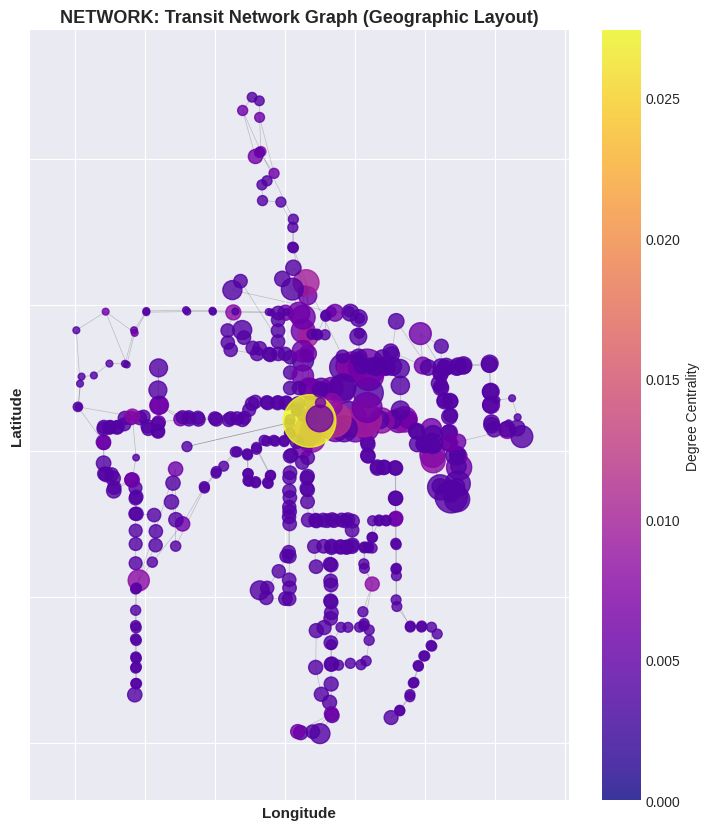

In [ ]:
# ============================================================================
# STEP 6: NETWORK GRAPH VISUALIZATIONS
# ============================================================================
print("\n[6/7] Creating NETWORK GRAPH visualizations...")

fig_network = plt.figure(figsize=(20, 10))
gs_net = fig_network.add_gridspec(1, 2, wspace=0.3)

# Plot 1: Full Network Graph
ax_net1 = fig_network.add_subplot(gs_net[0, 0])

# Use geographic positions
pos = {stop_id: (data['lon'], data['lat'])
       for stop_id, data in G.nodes(data=True)}

# Draw network
node_sizes = [G.nodes[node]['trips'] * 2 for node in G.nodes()]
node_colors = [degree_centrality[node] for node in G.nodes()]

nx.draw_networkx_edges(G, pos, alpha=0.2, width=0.5, ax=ax_net1)
nodes = nx.draw_networkx_nodes(G, pos, node_size=node_sizes,
                               node_color=node_colors, cmap='plasma',
                               alpha=0.8, ax=ax_net1)

ax_net1.set_title('NETWORK: Transit Network Graph (Geographic Layout)',
                  fontsize=13, fontweight='bold')
ax_net1.set_xlabel('Longitude', fontsize=11, fontweight='bold')
ax_net1.set_ylabel('Latitude', fontsize=11, fontweight='bold')
plt.colorbar(nodes, ax=ax_net1, label='Degree Centrality')

In [16]:
# ============================================================================
# STEP 6: GEPHI-STYLE NETWORK VISUALIZATIONS
# ============================================================================
print("\n[6/8] Creating GEPHI-STYLE network visualizations...")

# Get largest connected component for cleaner visualization
largest_cc = max(nx.connected_components(G), key=len)
G_main = G.subgraph(largest_cc).copy()

fig_network = plt.figure(figsize=(20, 14))
gs = fig_network.add_gridspec(2, 2, hspace=0.3, wspace=0.3)

# Layout 1: Force-Directed (Spring Layout) - Most similar to Gephi's ForceAtlas2
ax_n1 = fig_network.add_subplot(gs[0, :])
pos_spring = nx.spring_layout(G_main, k=1.5, iterations=100, seed=42, weight='weight')

# Get node attributes
node_sizes = [G_main.nodes[node]['trips'] * 5 for node in G_main.nodes()]
node_colors = [degree_centrality.get(node, 0) for node in G_main.nodes()]
edge_weights = [G_main[u][v]['weight'] / 5 for u, v in G_main.edges()]

# Draw edges
nx.draw_networkx_edges(G_main, pos_spring, width=edge_weights,
                       alpha=0.4, edge_color='#999999', ax=ax_n1)

# Draw nodes
nodes1 = nx.draw_networkx_nodes(G_main, pos_spring, node_size=node_sizes,
                                node_color=node_colors, cmap='plasma',
                                alpha=0.9, edgecolors='black', linewidths=1.5, ax=ax_n1)

# Add labels for top hubs only
hub_nodes = sorted(G_main.nodes(), key=lambda x: degree_centrality.get(x, 0), reverse=True)[:10]
hub_labels = {node: G_main.nodes[node]['name'][:15] for node in hub_nodes}
nx.draw_networkx_labels(G_main, pos_spring, hub_labels, font_size=8,
                        font_weight='bold', ax=ax_n1)

ax_n1.set_title('NETWORK GRAPH: Force-Directed Layout (Gephi ForceAtlas2 Style)',
                fontsize=14, fontweight='bold', pad=20)
ax_n1.axis('off')
cbar1 = plt.colorbar(nodes1, ax=ax_n1, label='Degree Centrality', fraction=0.046, pad=0.04)
ax_n1.margins(0.1)

# Layout 2: Circular Layout
ax_n2 = fig_network.add_subplot(gs[1, 0])
pos_circular = nx.circular_layout(G_main)

nx.draw_networkx_edges(G_main, pos_circular, width=edge_weights,
                       alpha=0.3, edge_color='#999999', ax=ax_n2)
nodes2 = nx.draw_networkx_nodes(G_main, pos_circular, node_size=node_sizes,
                                node_color=node_colors, cmap='viridis',
                                alpha=0.9, edgecolors='black', linewidths=1.5, ax=ax_n2)

ax_n2.set_title('NETWORK: Circular Layout', fontsize=12, fontweight='bold')
ax_n2.axis('off')
plt.colorbar(nodes2, ax=ax_n2, label='Centrality', fraction=0.046, pad=0.04)

# Layout 3: Kamada-Kawai (Energy-based)
ax_n3 = fig_network.add_subplot(gs[1, 1])
pos_kk = nx.kamada_kawai_layout(G_main, weight='weight')

nx.draw_networkx_edges(G_main, pos_kk, width=edge_weights,
                       alpha=0.3, edge_color='#999999', ax=ax_n3)
nodes3 = nx.draw_networkx_nodes(G_main, pos_kk, node_size=node_sizes,
                                node_color=node_colors, cmap='coolwarm',
                                alpha=0.9, edgecolors='black', linewidths=1.5, ax=ax_n3)

ax_n3.set_title('NETWORK: Kamada-Kawai Layout', fontsize=12, fontweight='bold')
ax_n3.axis('off')
plt.colorbar(nodes3, ax=ax_n3, label='Centrality', fraction=0.046, pad=0.04)

plt.savefig('3_network_graphs_gephi_style.png', dpi=300, bbox_inches='tight', facecolor='white')
print("✓ Saved: 3_network_graphs_gephi_style.png")
plt.close()


[6/8] Creating GEPHI-STYLE network visualizations...
✓ Saved: 3_network_graphs_gephi_style.png


In [17]:
# ============================================================================
# STEP 7: Network Metrics
# ============================================================================
print("\n[7/8] Creating network metrics visualizations...")

fig_metrics, axes_m = plt.subplots(2, 2, figsize=(16, 10))
fig_metrics.suptitle('NETWORK METRICS: Centrality Analysis',
                     fontsize=16, fontweight='bold', y=0.995)

# Degree Centrality Distribution
ax_m1 = axes_m[0, 0]
degree_vals = list(degree_centrality.values())
ax_m1.hist(degree_vals, bins=30, color='#2E86AB', edgecolor='black', alpha=0.8)
ax_m1.axvline(np.mean(degree_vals), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(degree_vals):.3f}')
ax_m1.set_xlabel('Degree Centrality', fontsize=11, fontweight='bold')
ax_m1.set_ylabel('Number of Stops', fontsize=11, fontweight='bold')
ax_m1.set_title('Degree Centrality Distribution', fontsize=12, fontweight='bold')
ax_m1.legend()
ax_m1.grid(axis='y', alpha=0.4, linestyle='--')

# Betweenness Centrality Distribution
ax_m2 = axes_m[0, 1]
betweenness_vals = list(betweenness_centrality.values())
ax_m2.hist(betweenness_vals, bins=30, color='#F77F00', edgecolor='black', alpha=0.8)
ax_m2.axvline(np.mean(betweenness_vals), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(betweenness_vals):.3f}')
ax_m2.set_xlabel('Betweenness Centrality', fontsize=11, fontweight='bold')
ax_m2.set_ylabel('Number of Stops', fontsize=11, fontweight='bold')
ax_m2.set_title('Betweenness Centrality Distribution', fontsize=12, fontweight='bold')
ax_m2.legend()
ax_m2.grid(axis='y', alpha=0.4, linestyle='--')

# Top Connected Stops
ax_m3 = axes_m[1, 0]
top_degree = stops_with_freq.nlargest(12, 'degree_centrality')
bars_deg = ax_m3.barh(range(len(top_degree)), top_degree['degree_centrality'],
                       color='#06A77D', edgecolor='black', linewidth=1.5)
ax_m3.set_yticks(range(len(top_degree)))
ax_m3.set_yticklabels(top_degree['stop_name'], fontsize=9)
ax_m3.set_xlabel('Degree Centrality', fontsize=11, fontweight='bold')
ax_m3.set_title('Top 12 Most Connected Stops', fontsize=12, fontweight='bold')
ax_m3.invert_yaxis()
ax_m3.grid(axis='x', alpha=0.4, linestyle='--')

# Network Properties Summary
ax_m4 = axes_m[1, 1]
ax_m4.axis('off')

network_stats = {
    'Total Nodes (Stops)': G.number_of_nodes(),
    'Total Edges (Connections)': G.number_of_edges(),
    'Average Degree': f"{np.mean(degree_vals):.3f}",
    'Network Density': f"{nx.density(G):.3f}",
    'Avg. Clustering Coefficient': f"{nx.average_clustering(G):.3f}",
    'Number of Components': nx.number_connected_components(G),
    'Largest Component Size': len(largest_cc),
    'Average Shortest Path*': 'N/A (Disconnected)'
}

# Try to calculate avg shortest path if connected
if nx.is_connected(G):
    network_stats['Average Shortest Path*'] = f"{nx.average_shortest_path_length(G):.2f}"

table_data = [[key, str(value)] for key, value in network_stats.items()]
table = ax_m4.table(cellText=table_data, colLabels=['Metric', 'Value'],
                   cellLoc='left', loc='center',
                   colWidths=[0.6, 0.4])
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.5)

# Style the table
for i in range(len(table_data) + 1):
    if i == 0:
        table[(i, 0)].set_facecolor('#2E86AB')
        table[(i, 1)].set_facecolor('#2E86AB')
        table[(i, 0)].set_text_props(weight='bold', color='white')
        table[(i, 1)].set_text_props(weight='bold', color='white')
    else:
        table[(i, 0)].set_facecolor('#E8F4F8' if i % 2 == 0 else 'white')
        table[(i, 1)].set_facecolor('#E8F4F8' if i % 2 == 0 else 'white')

ax_m4.set_title('Network Properties Summary', fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('4_network_metrics.png', dpi=300, bbox_inches='tight', facecolor='white')
print("✓ Saved: 4_network_metrics.png")
plt.close()


[7/8] Creating network metrics visualizations...
✓ Saved: 4_network_metrics.png


In [18]:
# ============================================================================
# STEP 8: Interactive Map
# ============================================================================
print("\n[8/8] Creating interactive map...")

m = folium.Map(location=[lat_center, lon_center], zoom_start=13, tiles='OpenStreetMap')
folium.TileLayer('cartodbpositron', name='Light Map').add_to(m)
folium.TileLayer('cartodbdark_matter', name='Dark Map').add_to(m)

stops_group = folium.FeatureGroup(name='Bus Stops', show=True)
network_group = folium.FeatureGroup(name='Transit Network', show=True)
hubs_group = folium.FeatureGroup(name='Transit Hubs', show=True)

# Add network edges
pos_geo = {stop_id: (data['lon'], data['lat']) for stop_id, data in G.nodes(data=True)}
for u, v in G.edges():
    if u in pos_geo and v in pos_geo:
        coords = [(pos_geo[u][1], pos_geo[u][0]), (pos_geo[v][1], pos_geo[v][0])]
        weight = G[u][v]['weight']
        folium.PolyLine(coords, weight=max(weight/10, 1), color='blue',
                       opacity=0.4).add_to(network_group)

# Add stops
for idx, row in stops_with_freq.iterrows():
    trips = row['daily_trips']
    if trips > 50:
        color, radius = 'darkred', 8
    elif trips > 20:
        color, radius = 'orange', 6
    else:
        color, radius = 'lightblue', 4

    popup_text = f"""
    <b>{row['stop_name']}</b><br>
    Daily Trips: {int(trips)}<br>
    Degree Centrality: {row['degree_centrality']:.3f}<br>
    Betweenness: {row['betweenness_centrality']:.3f}
    """

    folium.CircleMarker([row['stop_lat'], row['stop_lon']], radius=radius,
                       popup=folium.Popup(popup_text, max_width=250),
                       color='black', fillColor=color, fillOpacity=0.7,
                       weight=1).add_to(stops_group)

# Add hubs
for idx, row in hubs.iterrows():
    folium.Marker([row['stop_lat'], row['stop_lon']],
                 popup=f"<b>HUB: {row['stop_name']}</b><br>Hub Score: {row['hub_score']:.2f}",
                 icon=folium.Icon(color='red', icon='star', prefix='fa')).add_to(hubs_group)

heat_data = [[row['stop_lat'], row['stop_lon'], row['daily_trips']]
             for idx, row in stops_with_freq.iterrows() if row['daily_trips'] > 0]
plugins.HeatMap(heat_data, name='Service Heatmap', show=False).add_to(m)

stops_group.add_to(m)
network_group.add_to(m)
hubs_group.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)

m.save('5_interactive_map.html')
print("✓ Saved: 5_interactive_map.html")


[8/8] Creating interactive map...
✓ Saved: 5_interactive_map.html


In [20]:
# ============================================================================
# Generate Insights Report
# ============================================================================
print("\n[BONUS] Generating insights report...")

# Calculate geographic ranges for report
lat_range = stops['stop_lat'].max() - stops['stop_lat'].min()
lon_range = stops['stop_lon'].max() - stops['stop_lon'].min()

insights = f"""
=============================================================================
BLOOMINGTON TRANSIT MULTIMODAL ANALYSIS - KEY INSIGHTS
=============================================================================

TEMPORAL INSIGHTS:
-----------------
1. Peak Service Hours: {hourly_service.loc[hourly_service['num_stops'].idxmax(), 'hour']}:00
   (with {hourly_service['num_stops'].max()} stop events)

2. Service Distribution:
   - Morning Peak (7-9 AM): {len(morning_peak):,} stop events ({len(morning_peak)/len(stop_times)*100:.1f}%)
   - Evening Peak (4-6 PM): {len(evening_peak):,} stop events ({len(evening_peak)/len(stop_times)*100:.1f}%)
   - Off-Peak: {len(off_peak):,} stop events ({len(off_peak)/len(stop_times)*100:.1f}%)

3. Service Frequency Categories:
   - High Frequency Stops (>50 trips/day): {len(stops_with_freq[stops_with_freq['daily_trips'] > 50])}
   - Medium Frequency (21-50 trips/day): {len(stops_with_freq[(stops_with_freq['daily_trips'] > 20) & (stops_with_freq['daily_trips'] <= 50)])}
   - Low Frequency (1-20 trips/day): {len(stops_with_freq[(stops_with_freq['daily_trips'] > 0) & (stops_with_freq['daily_trips'] <= 20)])}
   - Inactive Stops: {len(stops_with_freq[stops_with_freq['daily_trips'] == 0])}

GEOSPATIAL INSIGHTS:
-------------------
1. Service Coverage:
   - Total Transit Area: {lat_range:.3f}° lat × {lon_range:.3f}° lon
   - Geographic Center: ({lat_center:.5f}, {lon_center:.5f})

2. Top 5 Busiest Stops:
{chr(10).join([f"   {i+1}. {row['stop_name']}: {int(row['daily_trips'])} trips/day" for i, (idx, row) in enumerate(stops_with_freq.nlargest(5, 'daily_trips').iterrows())])}

3. Transit Hub Identification:
   - {len(hubs)} major transit hubs identified
   - Hubs combine high connectivity AND high service frequency

NETWORK INSIGHTS:
----------------
1. Network Structure:
   - Total Nodes: {G.number_of_nodes()} stops
   - Total Edges: {G.number_of_edges()} connections
   - Network Density: {nx.density(G):.3f}
   - Connected Components: {nx.number_connected_components(G)}

2. Centrality Analysis:
   - Avg Degree Centrality: {np.mean(degree_vals):.3f}
   - Avg Betweenness Centrality: {np.mean(betweenness_vals):.3f}
   - Clustering Coefficient: {nx.average_clustering(G):.3f}

3. Most Connected Stops (Highest Degree Centrality):
{chr(10).join([f"   {i+1}. {row['stop_name']}: {row['degree_centrality']:.3f}" for i, (idx, row) in enumerate(stops_with_freq.nlargest(5, 'degree_centrality').iterrows())])}

RECOMMENDATIONS FOR STAKEHOLDERS:
---------------------------------
1. City Planners:
   - Focus infrastructure investments on identified transit hubs
   - Improve first/last mile connectivity at low-centrality stops
   - Consider adding bike-sharing stations at high-frequency stops

2. Transit Authority:
   - Optimize off-peak service based on temporal patterns
   - Enhance connections at high betweenness centrality stops (transfer points)
   - Address service gaps in low-density areas

3. Riders & Accessibility Advocates:
   - Interactive map shows real-time coverage and connectivity
   - High-frequency corridors offer reliable service
   - Hub locations ideal for multimodal transfers

=============================================================================
FILES GENERATED:
  1. 1_temporal_analysis.png
  2. 2_geospatial_analysis.png
  3. 3_network_graphs_gephi_style.png
  4. 4_network_metrics.png
  5. 5_interactive_map.html
=============================================================================
"""

with open('INSIGHTS_REPORT.txt', 'w') as f:
    f.write(insights)

print(insights)
print("\n✓ Saved: INSIGHTS_REPORT.txt")
print("\n" + "=" * 70)
print("ALL VISUALIZATIONS COMPLETE!")
print("=" * 70)


[BONUS] Generating insights report...

BLOOMINGTON TRANSIT MULTIMODAL ANALYSIS - KEY INSIGHTS

TEMPORAL INSIGHTS:
-----------------
1. Peak Service Hours: 13:00 
   (with 2367 stop events)

2. Service Distribution:
   - Morning Peak (7-9 AM): 5,564 stop events (19.6%)
   - Evening Peak (4-6 PM): 5,967 stop events (21.1%)
   - Off-Peak: 16,803 stop events (59.3%)

3. Service Frequency Categories:
   - High Frequency Stops (>50 trips/day): 175
   - Medium Frequency (21-50 trips/day): 288
   - Low Frequency (1-20 trips/day): 26
   - Inactive Stops: 23

GEOSPATIAL INSIGHTS:
-------------------
1. Service Coverage:
   - Total Transit Area: 0.087° lat × 0.128° lon
   - Geographic Center: (39.15966, -86.53370)

2. Top 5 Busiest Stops:
   1. Transit Center: 716 trips/day
   2. 10th St & Eagleson @ Wells Library: 348 trips/day
   3. 3rd St @ IU Biology: 321 trips/day
   4. 3rd & Eagleson: 321 trips/day
   5. 3rd St & Indiana Ave: 321 trips/day

3. Transit Hub Identification:
   - 10 major tran